# Decode the Bioreactor — 02 Mechanistic model
Simulation per batch: start from the day-0 sample → solve the bucket equations with `scipy.integrate.solve_ivp` (LSODA, adaptive step, rtol 1e-6) up to the next feed → apply the mixing jump (volume up, dilute, add feed contents) → repeat to the end. A sample taken at the same time as a feed is read *before* the feed.
Parameters are **global** (shared by all batches), fitted by robust least squares on log residuals. A batch is predicted from its day-0 values + feed schedule only.

**Fitting strategy** (`fit_staged` in `src/bioreactor/fit.py`):
1. starting values estimated from the data (early growth rate, substrate yield, byproduct yield, byproduct consumption),
2. staged fit — cell parameters on VCD/TCD, then substrate parameters on substrate, then byproduct parameters on byproduct,
3. joint fit of all parameters on all states, optionally multi-start.

Model and equations: `src/bioreactor/model.py`. Fit: `src/bioreactor/fit.py`.
**Runtime**: one simulation of ~30 batches ≈ 0.3 s; a staged fit takes ~5–15 min depending on `MAX_NFEV`.

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from bioreactor.data import load, to_arrays, STATES
from bioreactor.model import simulate, predict_at_obs, NAMES, P0
from bioreactor.fit import fit, fit_staged, initial_from_data

df, tmpl, train_ids, test_ids = load(ROOT / "data")
splits = pd.read_csv(ROOT / "outputs" / "splits.csv")
dev_ids = splits.query("role == 'dev'").batch_id.tolist()
hold_ids = splits.query("role == 'holdout'").batch_id.tolist()
fold_of = splits.query("role == 'dev'").set_index("batch_id").fold.to_dict()

# residual scale per state = spread of the measurements (puts VCD and g/L on equal footing)
meas = df[df.batch_id.isin(dev_ids) & df.vcd.notna()]
SCALE = meas[STATES].std().values
print("dev:", len(dev_ids), " holdout:", len(hold_ids), " test:", len(test_ids))
print("residual scale:", dict(zip(STATES, SCALE.round(3))))

dev: 39  holdout: 10  test: 12
residual scale: {'vcd': 10.531, 'tcd': 11.032, 'substrate': 0.994, 'byproduct': 0.784}


## Helpers: metrics, baseline, plots

In [2]:
def metrics(arr, preds, eps=1e-6):
    """Per state over all samples of arr:
    RMSE, NRMSE (= RMSE / mean observed), R2, and MAPE [%] = 100 * mean(|pred - obs| / |obs|).
    Row 'all' = MAPE pooled over all states and samples (other columns not meaningful across units)."""
    Y = np.vstack(arr.obs_y); Yh = np.vstack(preds)
    rmse = np.sqrt(np.mean((Yh - Y) ** 2, axis=0))
    r2 = 1 - np.sum((Yh - Y) ** 2, axis=0) / np.sum((Y - Y.mean(0)) ** 2, axis=0)
    ape = np.abs(Yh - Y) / np.maximum(np.abs(Y), eps)   # observed values are all > 0.2 here
    out = pd.DataFrame({"RMSE": rmse, "NRMSE": rmse / Y.mean(0), "R2": r2,
                        "MAPE_%": 100 * ape.mean(axis=0)}, index=STATES)
    out.loc["all"] = [np.nan, np.nan, np.nan, 100 * ape.mean()]
    return out.round(3)

def baseline_preds(train_ids_, arr):
    """Naive reference: median training curve per day (ignores day-0 values and feeds)."""
    m = df[df.batch_id.isin(train_ids_) & df.vcd.notna()].copy()
    m["day"] = m.elapsed_time.round().astype(int)
    med = m.groupby("day")[STATES].median()
    return [med.reindex(np.round(t).astype(int)).values for t in arr.obs_t]

def plot_fit(p, arr, ids=None, title=""):
    ids = ids or arr.ids[:4]
    traj = simulate(p, arr)
    fig, ax = plt.subplots(len(ids), 4, figsize=(16, 2.8 * len(ids)), squeeze=False)
    for r, b in enumerate(ids):
        j = arr.ids.index(b)
        for c, v in enumerate(STATES):
            a = ax[r, c]
            a.plot(arr.t, traj[:, j, c], "-", c="tab:blue", label="model")
            a.plot(arr.obs_t[j], arr.obs_y[j][:, c], "o", c="k", ms=4, label="data")
            a.set_title(f"{b}: {v}", fontsize=9)
    ax[0, 0].legend(fontsize=8); fig.suptitle(title); fig.tight_layout(); plt.show()

def parity(arr, preds, title=""):
    Y = np.vstack(arr.obs_y); Yh = np.vstack(preds)
    fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
    for c, v in enumerate(STATES):
        ax[c].scatter(Y[:, c], Yh[:, c], s=8, alpha=0.6)
        lo, hi = min(Y[:, c].min(), Yh[:, c].min()), max(Y[:, c].max(), Yh[:, c].max())
        ax[c].plot([lo, hi], [lo, hi], "k--", lw=1); ax[c].set_xlabel("observed"); ax[c].set_ylabel("predicted"); ax[c].set_title(v)
    fig.suptitle(title); fig.tight_layout(); plt.show()

## 1. Sanity check of the simulator (no fitting)
Initial-guess parameters on a few dev batches. The curves will be off — the point is that the simulation runs, feeds produce jumps, and nothing goes negative / explodes.

one simulation of 39 batches: 0.08 s
any NaN: False  min value: 0.007


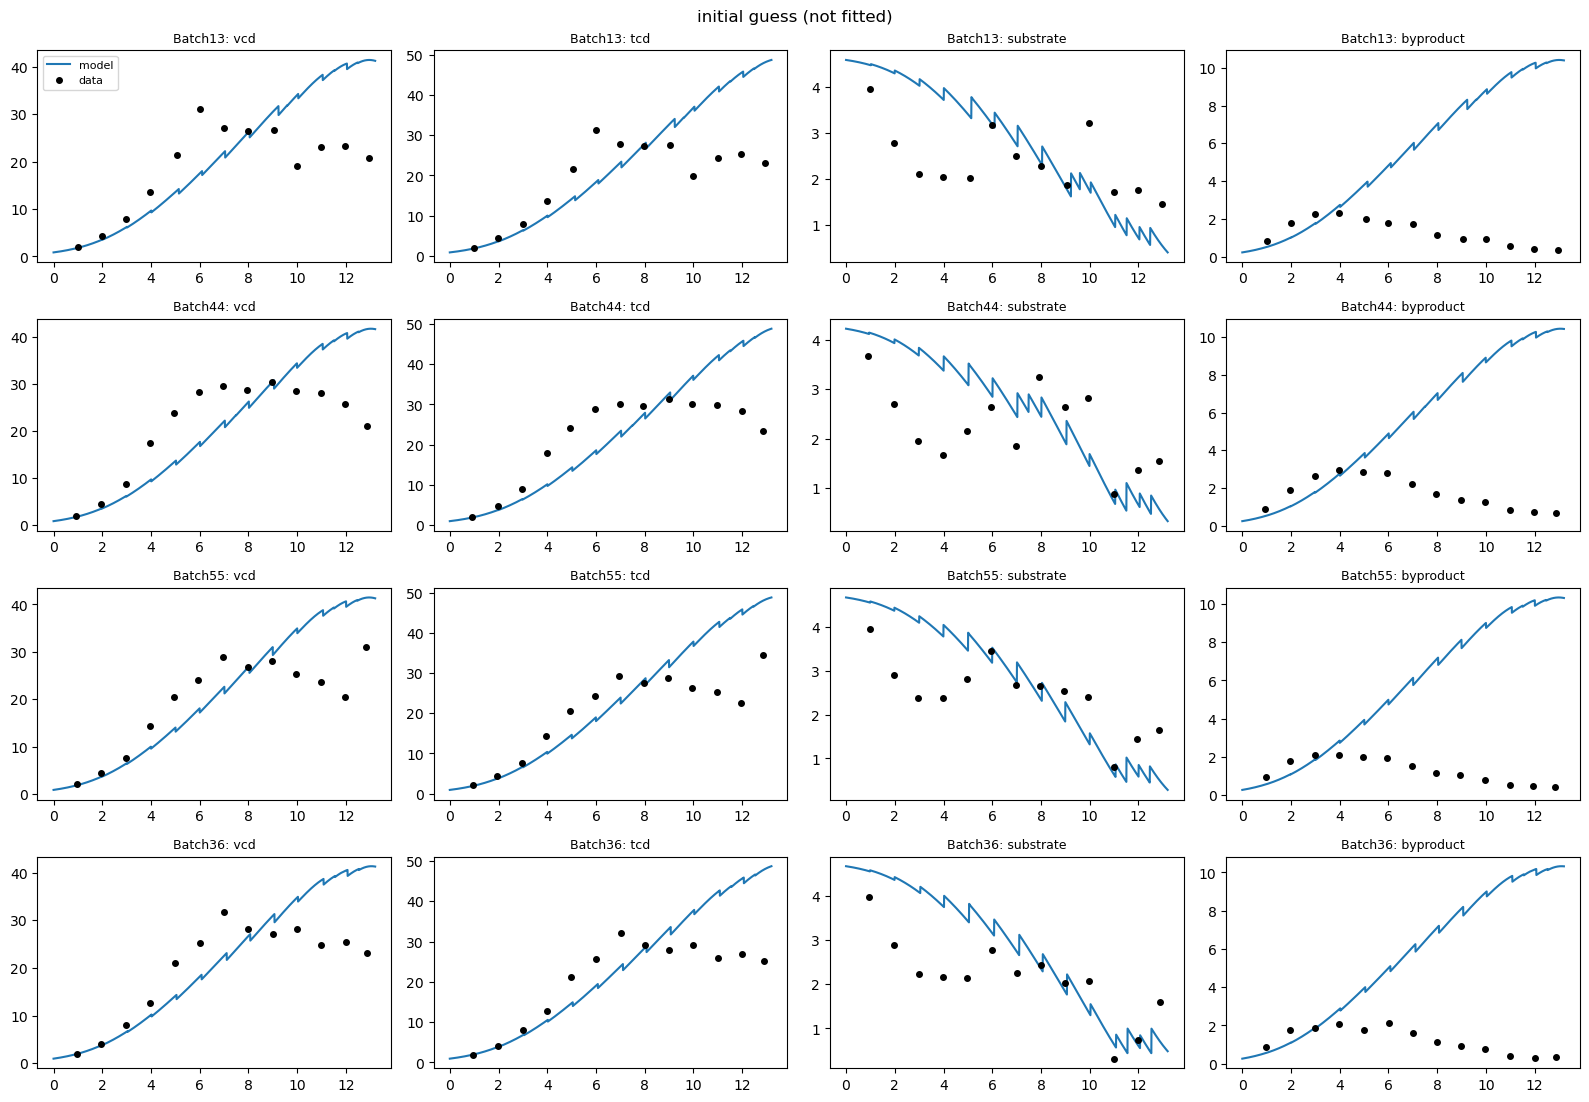

In [3]:
arr_dev = to_arrays(df, dev_ids)
t0 = time.time(); traj = simulate(P0, arr_dev); print(f"one simulation of {len(dev_ids)} batches: {time.time()-t0:.2f} s")
print("any NaN:", np.isnan(traj).any(), " min value:", traj.min().round(3))
plot_fit(P0, arr_dev, title="initial guess (not fitted)")

## 2. Solver check: solve_ivp vs. Euler
`simulate` / `predict_at_obs` use `solve_ivp` by default (`solver="ivp"`); `solver="euler"` is the old fixed-step version. Large differences = Euler too coarse.

In [5]:
arr3 = to_arrays(df, dev_ids[:5])
p_chk = initial_from_data(df, dev_ids)
for name, pp in [("P0", P0), ("data-based start", p_chk)]:
    t0 = time.time(); a = np.vstack(predict_at_obs(pp, arr3)); t_ivp = time.time() - t0
    t0 = time.time(); b = np.vstack(predict_at_obs(pp, arr3)); t_eu = time.time() - t0
    rel = np.abs(a - b).max(axis=0) / np.abs(a).max(axis=0)
    print(f"{name:17s} max rel. diff ivp vs euler: {dict(zip(STATES, rel.round(4)))}  (ivp {t_ivp:.2f} s, euler {t_eu:.2f} s)")

P0                max rel. diff ivp vs euler: {'vcd': 0.0, 'tcd': 0.0, 'substrate': 0.0, 'byproduct': 0.0}  (ivp 0.07 s, euler 0.06 s)
data-based start  max rel. diff ivp vs euler: {'vcd': 0.0, 'tcd': 0.0, 'substrate': 0.0, 'byproduct': 0.0}  (ivp 0.06 s, euler 0.07 s)


## 3. Fit on one CV fold
Train on 4 folds of the dev set, validate on the held-out fold.
- `MAX_NFEV_STAGE`: evaluations per stage (cells / substrate / byproduct), `MAX_NFEV`: joint fit. If the joint fit stops with *"maximum number of function evaluations is exceeded"*, raise `MAX_NFEV` or continue from `p_fold` (cell below).
- `N_STARTS > 1`: extra joint fits from randomly perturbed starts (±30 %), best cost kept.

In [6]:
FOLD = 0
MAX_NFEV_STAGE = 20   # per stage
MAX_NFEV = 60         # joint fit (also used for CV / hold-out / final below)
N_STARTS = 1
# fit settings used by every fit below (see src/bioreactor/fit.py)
#   RESIDUAL: "log" (relative error, matches MAPE) or "scaled" (absolute error / std, old behaviour)
#   LOSS:     "soft_l1" (robust to outliers) or "linear" (plain least squares)
FIT_KW = dict(residual="log", loss="soft_l1", f_scale=0.1)

tr_ids = [b for b in dev_ids if fold_of[b] != FOLD]
va_ids = [b for b in dev_ids if fold_of[b] == FOLD]
arr_tr, arr_va = to_arrays(df, tr_ids), to_arrays(df, va_ids)

t0 = time.time()
p_start = initial_from_data(df, tr_ids)
print("data-based starting values:", pd.Series(p_start, index=NAMES).round(4).to_dict())
p_fold, fit_log = fit_staged(arr_tr, SCALE, p_init=p_start, max_nfev_stage=MAX_NFEV_STAGE,
                             max_nfev_final=MAX_NFEV, n_starts=N_STARTS, **FIT_KW)
print(f"fit time {time.time()-t0:.0f} s"); display(fit_log)
pd.Series(p_fold, index=NAMES).round(4)

data-based starting values: {'mu_max': 0.9685, 'Ks': 0.1, 'KI': 10.0, 'KN': 0.05, 'Yxn': 10.0, 'Nb': 7.0, 'kd0': 0.005, 'kd1': 0.01, 'KdN': 0.1, 'klys': 0.01, 'Yxs': 1.3639, 'ms': 0.01, 'Sb': 50.0, 'Ss': 300.0, 'Ypx': 0.6417, 'qPc': 0.0128, 'KPc': 0.5}
start      cost 10221.332
cells      cost  6774.750  (10 s)
substrate  cost   942.646  (17 s)
byproduct  cost   648.305  (23 s)
joint #0    cost    23.180  (66 s)  `xtol` termination condition is satisfied.
fit time 66 s


,step,cost,time_s
0,start,10221.331949,0.071149
1,cells,6774.749566,9.990700
2,substrate,942.645860,16.823971
3,byproduct,648.304877,22.814765
4,joint#0,23.180102,66.328366


mu_max      2.6983
Ks          0.2008
KI          5.0054
KN          1.4921
Yxn        21.3579
Nb          4.4254
kd0         0.0001
kd1         0.3908
KdN         0.0924
klys        1.0000
Yxs         3.9966
ms          0.0981
Sb         75.1017
Ss        160.3346
Ypx         0.4174
qPc         0.7603
KPc         9.9317
dtype: float64

In [7]:
# optional: continue the joint fit from where it stopped (run again until the cost stops dropping)
CONTINUE = False
if CONTINUE:
    t0 = time.time()
    p_fold, sol = fit(arr_tr, SCALE, p_init=p_fold, max_nfev=MAX_NFEV, **FIT_KW)
    print(f"{time.time()-t0:.0f} s, cost {sol.cost:.3f}, {sol.message}")

fold 0 — mechanistic model on unseen batches:


,RMSE,NRMSE,R2,MAPE_%
vcd,2.848,0.139,0.909,10.355
tcd,3.163,0.148,0.897,11.097
substrate,0.340,0.148,0.816,13.507
byproduct,0.265,0.181,0.865,16.986
all,NaN,NaN,NaN,12.986


baseline (median training curve):


,RMSE,NRMSE,R2,MAPE_%
vcd,2.246,0.109,0.944,8.163
tcd,2.294,0.107,0.946,8.108
substrate,0.269,0.117,0.885,9.974
byproduct,0.178,0.122,0.939,11.931
all,NaN,NaN,NaN,9.544


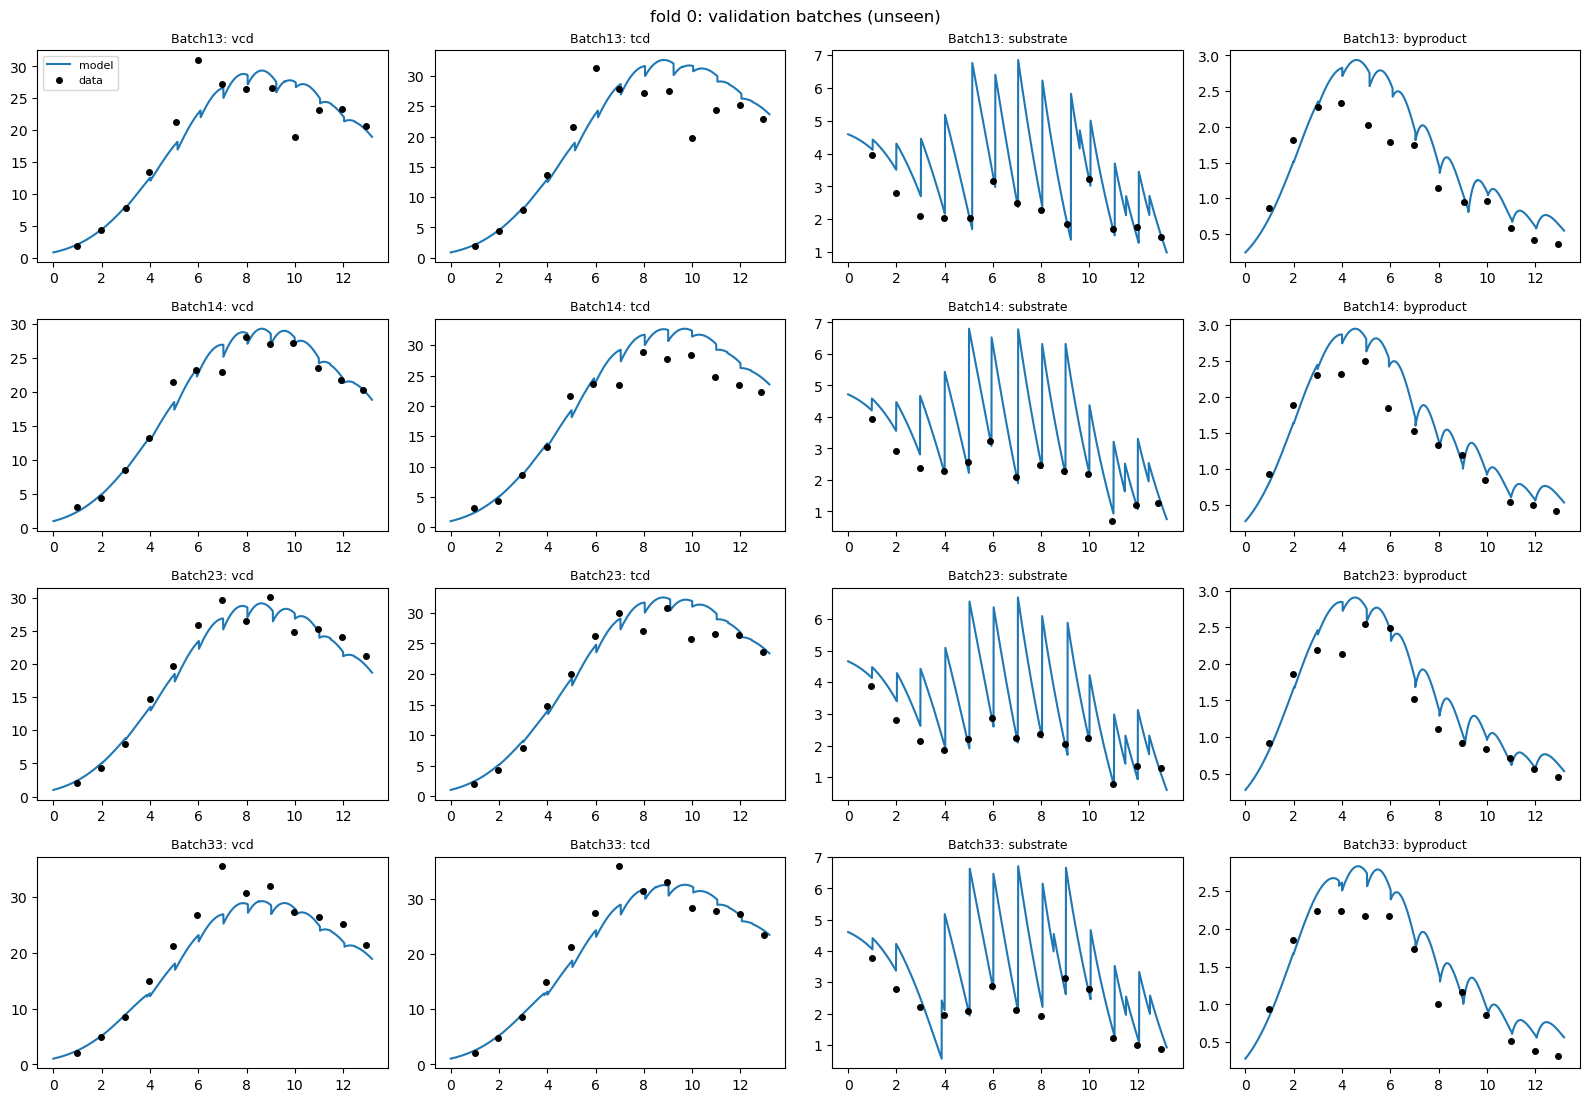

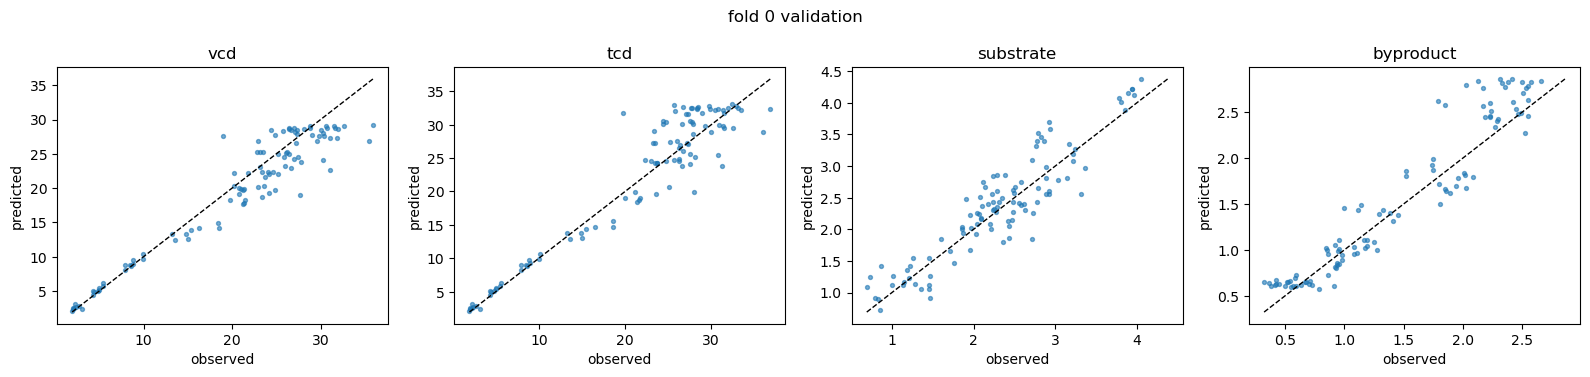

In [8]:
pred_va = predict_at_obs(p_fold, arr_va)
print(f"fold {FOLD} — mechanistic model on unseen batches:"); display(metrics(arr_va, pred_va))
print("baseline (median training curve):"); display(metrics(arr_va, baseline_preds(tr_ids, arr_va)))
plot_fit(p_fold, arr_va, title=f"fold {FOLD}: validation batches (unseen)")
parity(arr_va, pred_va, title=f"fold {FOLD} validation")

In [9]:
# training fit, to compare with validation (big gap = overfitting, both bad = model structure)
display(metrics(arr_tr, predict_at_obs(p_fold, arr_tr)))

,RMSE,NRMSE,R2,MAPE_%
vcd,2.984,0.144,0.904,11.016
tcd,3.127,0.145,0.904,11.879
substrate,0.357,0.156,0.808,14.726
byproduct,0.280,0.183,0.859,16.144
all,NaN,NaN,NaN,13.441


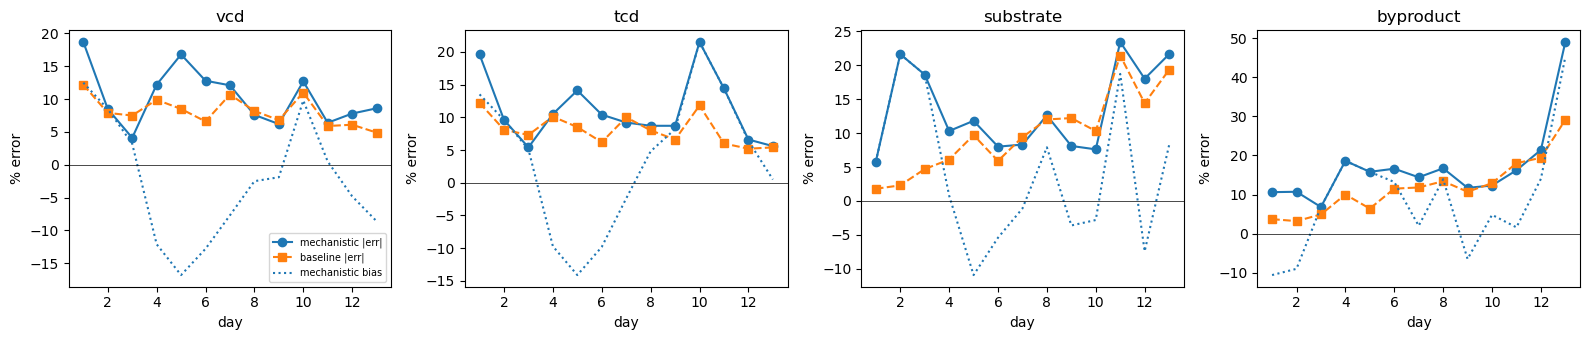

In [10]:
# where does the model miss? mean signed and absolute % error by day (validation fold)
def pct_err_by_day(arr, preds):
    Y = np.vstack(arr.obs_y); Yh = np.vstack(preds); T = np.round(np.concatenate(arr.obs_t)).astype(int)
    e = pd.DataFrame(100 * (Yh - Y) / Y, columns=STATES); e["day"] = T
    return e.groupby("day").mean().round(1), e.abs().groupby("day").mean().round(1)

bias_m, abs_m = pct_err_by_day(arr_va, pred_va)
bias_b, abs_b = pct_err_by_day(arr_va, baseline_preds(tr_ids, arr_va))
fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
for a, v in zip(ax, STATES):
    a.plot(abs_m.index, abs_m[v], "o-", label="mechanistic |err|"); a.plot(abs_b.index, abs_b[v], "s--", label="baseline |err|")
    a.plot(bias_m.index, bias_m[v], ":", c="tab:blue", label="mechanistic bias")
    a.axhline(0, c="k", lw=0.5); a.set_title(v); a.set_xlabel("day"); a.set_ylabel("% error")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## 4. Full 5-fold cross-validation
Run when section 3 looks reasonable. Each fold is fitted with the full staged procedure from its own data-based start (`WARM_START = False`), so no validation batch influences its own fit.
`WARM_START = True` starts every fold from `p_fold` instead — ~3x faster, but slightly optimistic (p_fold has seen the other folds' validation batches).

In [11]:
RUN_CV = False
WARM_START = False
if RUN_CV:
    cv_rows, cv_params = [], {}
    for f in range(5):
        tr_ = [b for b in dev_ids if fold_of[b] != f]; va_ = [b for b in dev_ids if fold_of[b] == f]
        a_tr, a_va = to_arrays(df, tr_), to_arrays(df, va_)
        if WARM_START:
            p_f, _ = fit(a_tr, SCALE, p_init=p_fold, max_nfev=MAX_NFEV, **FIT_KW)
        else:
            p_f, _ = fit_staged(a_tr, SCALE, p_init=initial_from_data(df, tr_), max_nfev_stage=MAX_NFEV_STAGE,
                                max_nfev_final=MAX_NFEV, n_starts=N_STARTS, verbose=False, **FIT_KW)
        cv_params[f] = p_f
        m_mech = metrics(a_va, predict_at_obs(p_f, a_va)).assign(model="mechanistic", fold=f)
        m_base = metrics(a_va, baseline_preds(tr_, a_va)).assign(model="baseline", fold=f)
        cv_rows += [m_mech, m_base]; print(f"fold {f} done")
    cv = pd.concat(cv_rows).rename_axis("state").reset_index()
    display(cv.groupby(["model", "state"])[["RMSE", "NRMSE", "R2", "MAPE_%"]].agg(["mean", "std"]).round(3))
    display(pd.DataFrame(cv_params, index=NAMES).round(4))  # parameter stability across folds

## 5. Hold-out check — run ONCE, at the end
Fit on all 39 dev batches, evaluate on the 10 hold-out batches. This is the honest estimate of performance on the hidden test set.

In [12]:
RUN_HOLDOUT = False
if RUN_HOLDOUT:
    arr_all_dev, arr_hold = to_arrays(df, dev_ids), to_arrays(df, hold_ids)
    p_dev, _ = fit(arr_all_dev, SCALE, p_init=p_fold, max_nfev=MAX_NFEV, **FIT_KW)
    pred_h = predict_at_obs(p_dev, arr_hold)
    display(metrics(arr_hold, pred_h)); display(metrics(arr_hold, baseline_preds(dev_ids, arr_hold)))
    plot_fit(p_dev, arr_hold, ids=hold_ids[:5], title="hold-out batches")

## 6. Final fit on all 49 batches → submission
Predicts the 12 test batches at the template time points and writes `outputs/submission_mechanistic.csv`.

In [13]:
RUN_FINAL = False
if RUN_FINAL:
    arr_all = to_arrays(df, train_ids)
    p_final, _ = fit(arr_all, SCALE, p_init=p_fold, max_nfev=MAX_NFEV, **FIT_KW)
    arr_test = to_arrays(df, test_ids, sample_mask="predict")
    preds = predict_at_obs(p_final, arr_test)
    failed = [b for b, y in zip(arr_test.ids, preds) if np.isnan(y).any()]
    assert not failed, f"simulation failed for {failed} - check p_final (fit converged?)"
    # fill the template batch by batch, in time order (times may differ in the last decimals)
    pred_of = {b: (ts, ys) for b, ts, ys in zip(arr_test.ids, arr_test.obs_t, preds)}
    sub = tmpl.copy()
    sub[STATES] = sub[STATES].astype(float)   # template columns are int zeros
    for b, g in sub.groupby("batch_id", sort=False):
        ts, ys = pred_of[b]
        order = np.argsort(ts)
        assert len(g) == len(ts), f"{b}: {len(g)} template rows vs {len(ts)} predictions"
        assert np.allclose(np.sort(g.elapsed_time.values), ts[order], atol=1e-3), f"{b}: time mismatch"
        sub.loc[g.sort_values("elapsed_time").index, STATES] = ys[order]
    assert sub[STATES].notna().all().all() and (sub[STATES] != 0).any(axis=1).all()
    sub.to_csv(ROOT / "outputs" / "submission_mechanistic.csv", index=False)
    pd.Series(p_final, index=NAMES).to_csv(ROOT / "outputs" / "params_mechanistic.csv")
    plot_fit(p_final, arr_test, ids=test_ids[:4], title="test batches (prediction only)")
    sub.head()